# Notebook 03 — Clasificación temporal y política de alertas

**Problema 7.** Dos horas antes de la salida, predecir si un vuelo saldrá con al menos 15 minutos de retraso ($Y=1$ si `min_retraso` $\ge15$) y decidir a qué vuelos enviarles una alerta, respetando unas condiciones operativas.

Los datos se ordenan en el tiempo y se usan en tres períodos consecutivos, cada uno con un papel distinto:

| Conjunto | Para qué se usa |
|---|---|
| Entrenamiento (primer 60 %) | Comparar modelos con validación cruzada temporal |
| Validación (del 60 % al 80 %) | Revisar las probabilidades y elegir la política de alertas |
| Prueba (último 20 %) | Una sola evaluación, al final |

La regresión logística (con y sin pesos de clase) es la implementación propia de `modelos.py`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# De scikit-learn usamos preprocesamiento, particiones y métricas.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, auc, average_precision_score, brier_score_loss,
                             confusion_matrix, f1_score, log_loss, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Modelo propio.
from modelos import SEMILLA, RegresionLogisticaGD

RESULTADOS = Path("resultados")
PARAMETROS = RESULTADOS / "parametros"
PARAMETROS.mkdir(parents=True, exist_ok=True)

SEED = SEMILLA     # generar_vuelos usa este nombre como semilla por defecto
GAP = 24           # una fila = una hora, así que 24 filas = un día

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## Datos

`generar_vuelos` es la función del notebook de clasificación de clase, copiada **sin cambiar su mecanismo**, y se llama con `n=9600, seed=2026`. Por dentro calcula una "probabilidad generadora" para sortear los retrasos, pero esa probabilidad no se devuelve ni se usa: el modelo solo ve los predictores y la etiqueta observada.

In [2]:
# Reutilizado de clase: generar_vuelos, copiada sin cambios (el enunciado exige no modificarla).
# Mejoras: ninguna en la función; se agrega afuera un id por vuelo y la etiqueta.
def generar_vuelos(n=9600, seed=SEED):
    rng = np.random.default_rng(seed)
    fecha = pd.date_range('2024-01-01', periods=n, freq='h')
    hora = ((fecha + pd.Timedelta(hours=2)).hour).to_numpy()
    progreso = np.linspace(0, 1, n)
    aerolinea = rng.choice(['Aero_A', 'Aero_B', 'Aero_C'], n, p=[0.50, 0.30, 0.20])
    origen = rng.choice(['BOG', 'MDE', 'CLO', 'CTG'], n)
    distancia = rng.uniform(200, 1800, n)
    lluvia = rng.gamma(shape=1.2, scale=2.0, size=n)
    viento = np.clip(rng.normal(15, 6, n), 0, 45)
    ocupacion = np.clip(rng.normal(77, 12, n), 25, 100)
    trafico = np.clip(rng.normal(45 + 10 * progreso, 13, n), 5, 100)
    # Probabilidad del simulador: combina factores conocidos antes de la salida.
    logit = (
        -5.3 + 1.1 * (trafico - 45) / 13
        + 0.8 * (lluvia - 2.4) / 2.2 + 0.7 * (viento - 15) / 6
        + 0.35 * (ocupacion - 77) / 12 + 0.55 * (hora >= 17)
        + 0.40 * (origen == 'BOG') + 0.45 * (aerolinea == 'Aero_C')
    )
    probabilidad_generadora = 1 / (1 + np.exp(-logit))
    # La etiqueta se sortea: vuelos similares pueden tener resultados distintos.
    positivo = rng.binomial(1, probabilidad_generadora)
    retraso = np.where(positivo == 1, rng.integers(15, 181, n), rng.integers(-10, 15, n))
    datos = pd.DataFrame({
        'fecha_prediccion': fecha, 'hora_salida': hora,
        'distancia_km': distancia, 'lluvia_pronosticada_mm': lluvia,
        'viento_pronosticado_kmh': viento, 'ocupacion_programada_pct': ocupacion,
        'trafico_programado': trafico, 'aerolinea': aerolinea,
        'origen': origen, 'min_retraso': retraso,
    })
    # Los faltantes afectan a predictores, nunca a la etiqueta observada.
    for columna in ['lluvia_pronosticada_mm', 'viento_pronosticado_kmh',
                    'ocupacion_programada_pct', 'aerolinea']:
        datos.loc[rng.random(n) < 0.06, columna] = np.nan
    return datos


# Datos ordenados en el tiempo, con un id estable y la etiqueta Y.
vuelos = generar_vuelos(n=9600, seed=2026).sort_values("fecha_prediccion").reset_index(drop=True)
vuelos.insert(0, "id_vuelo", np.arange(1, len(vuelos) + 1))     # 1, 2, ... en orden cronológico
vuelos["retrasado"] = (vuelos["min_retraso"] >= 15).astype(int)

NUMERICAS = ["hora_salida", "distancia_km", "lluvia_pronosticada_mm", "viento_pronosticado_kmh",
             "ocupacion_programada_pct", "trafico_programado"]
CATEGORICAS = ["aerolinea", "origen"]
PREDICTORES = NUMERICAS + CATEGORICAS
vuelos.head()

,id_vuelo,fecha_prediccion,hora_salida,distancia_km,lluvia_pronosticada_mm,viento_pronosticado_kmh,ocupacion_programada_pct,trafico_programado,aerolinea,origen,min_retraso,retrasado
0,1,2024-01-01 00:00:00,2,862.8348,2.2192,5.2833,69.7092,39.1817,Aero_A,MDE,11,0
1,2,2024-01-01 01:00:00,3,326.8961,4.1699,17.0507,62.3248,35.4055,Aero_B,CLO,0,0
2,3,2024-01-01 02:00:00,4,418.3571,0.7270,9.7587,67.7305,22.5180,Aero_A,MDE,1,0
3,4,2024-01-01 03:00:00,5,1415.5487,1.0526,NaN,72.9115,37.9272,Aero_A,CTG,4,0
4,5,2024-01-01 04:00:00,6,799.1430,0.6765,10.7799,68.0714,44.4690,Aero_A,BOG,9,0


## 7a. Diccionario, partición temporal y auditoría

### ¿Qué se conoce dos horas antes de la salida?

Un predictor solo es válido si se conoce en el momento de predecir. Usar algo que se conoce después sería hacer trampa (fuga de información).

| Variable | Tipo | ¿Se conoce 2 h antes? | Uso | Por qué |
|---|---|---|---|---|
| `fecha_prediccion` | fecha y hora | Sí | Solo para ordenar y partir | Es el momento de la predicción; usarla como predictor convertiría la tendencia en el tiempo en un atajo |
| `hora_salida` | entero (0–23) | Sí | Predictor | Hora del itinerario |
| `distancia_km` | numérica | Sí | Predictor | Distancia de la ruta programada |
| `lluvia_pronosticada_mm` | numérica | Sí | Predictor | Es un **pronóstico**, no la lluvia que realmente cayó |
| `viento_pronosticado_kmh` | numérica | Sí | Predictor | Pronóstico del clima |
| `ocupacion_programada_pct` | numérica | Sí | Predictor | Reservas conocidas al predecir |
| `trafico_programado` | numérica | Sí | Predictor | Tráfico planeado, no el observado |
| `aerolinea` | categórica | Sí | Predictor | Dato de la operación programada |
| `origen` | categórica | Sí | Predictor | Aeropuerto de salida |
| `min_retraso` | entera | **No** | Solo para definir $Y$ | Se conoce después de la salida; usarla sería fuga directa |

### Partición

Se usan los mismos cortes del notebook de clase:

- **Entrenamiento:** filas antes del corte del 60 %, sin las 24 filas justo antes del corte.
- **Validación:** filas desde el corte del 60 % hasta el del 80 %, sin las 24 filas justo antes del segundo corte.
- **Prueba:** filas desde el corte del 80 % hasta el final.

Cada fila es una hora, así que 24 filas son un día. Se supone que la etiqueta de un vuelo (si se retrasó o no) se conoce en menos de un día; al dejar un día de separación, ninguna etiqueta de un período queda "pendiente" cuando empieza el siguiente.

In [3]:
# Reutilizado de clase: separar_por_tiempo (cortes al 60 % y 80 % con exclusión de GAP filas).
# Mejoras: se registra el conjunto de cada id (incluidas las filas excluidas) y los rangos.
n_vuelos = len(vuelos)
corte_1 = int(n_vuelos * 0.60)          # primera fila de validación
corte_2 = int(n_vuelos * 0.80)          # primera fila de prueba
posicion = np.arange(n_vuelos)

# np.select asigna el primer nombre cuya condición se cumple; si ninguna se cumple, "prueba".
condiciones = [
    posicion < corte_1 - GAP,           # entrenamiento
    posicion < corte_1,                 # día de separación antes de validación
    posicion < corte_2 - GAP,           # validación
    posicion < corte_2,                 # día de separación antes de prueba
]
nombres = ["entrenamiento", "excluida (gap)", "validacion", "excluida (gap)"]
vuelos["conjunto"] = np.select(condiciones, nombres, default="prueba")

entrenamiento = vuelos[vuelos["conjunto"] == "entrenamiento"].reset_index(drop=True)
validacion = vuelos[vuelos["conjunto"] == "validacion"].reset_index(drop=True)
prueba = vuelos[vuelos["conjunto"] == "prueba"].reset_index(drop=True)

# Comprobaciones: más de un día entre períodos y ninguna variable prohibida entre los predictores.
for antes, despues in ((entrenamiento, validacion), (validacion, prueba)):
    separacion = despues["fecha_prediccion"].min() - antes["fecha_prediccion"].max()
    assert separacion > pd.Timedelta(hours=GAP)
    assert antes["id_vuelo"].max() + GAP < despues["id_vuelo"].min()
assert not {"min_retraso", "retrasado", "fecha_prediccion"} & set(PREDICTORES)

# Manifiesto de partición por id y rangos de cada conjunto.
vuelos[["id_vuelo", "fecha_prediccion", "conjunto"]].to_csv(RESULTADOS / "p7_particiones.csv", index=False)
rangos = vuelos.groupby("conjunto", sort=False).agg(
    n=("id_vuelo", "size"), id_min=("id_vuelo", "min"), id_max=("id_vuelo", "max"),
    inicio=("fecha_prediccion", "min"), fin=("fecha_prediccion", "max"))
rangos

,n,id_min,id_max,inicio,fin
conjunto,,,,,
entrenamiento,5736,1,5736,2024-01-01,2024-08-26 23:00:00
excluida (gap),48,5737,7680,2024-08-27,2024-11-15 23:00:00
validacion,1896,5761,7656,2024-08-28,2024-11-14 23:00:00
prueba,1920,7681,9600,2024-11-16,2025-02-03 23:00:00


### Auditoría en entrenamiento

Faltantes, tipos y distribuciones se revisan **solo en entrenamiento**. La proporción de retrasos de validación y de prueba no se calcula todavía.

In [4]:
X_ent = entrenamiento[PREDICTORES]
y_ent = entrenamiento["retrasado"].to_numpy()

auditoria = pd.DataFrame({
    "tipo": X_ent.dtypes.astype(str),
    "faltantes": X_ent.isna().sum(),
    "% faltantes": 100 * X_ent.isna().mean(),
    "valores únicos": X_ent.nunique(),
})
display(auditoria.round(2))
display(X_ent[NUMERICAS].describe().T.round(2))

# Conteo de cada categoría (dropna=False también cuenta los faltantes).
for col in CATEGORICAS:
    print(col, X_ent[col].value_counts(dropna=False).to_dict())
print(f"\nPrevalencia en entrenamiento: {y_ent.mean():.4f} ({y_ent.sum()} positivos de {len(y_ent)})")

,tipo,faltantes,% faltantes,valores únicos
hora_salida,int32,0,0.00,24
distancia_km,float64,0,0.00,5736
lluvia_pronosticada_mm,float64,359,6.26,5377
viento_pronosticado_kmh,float64,373,6.50,5332
ocupacion_programada_pct,float64,371,6.47,5225
trafico_programado,float64,0,0.00,5732
aerolinea,object,335,5.84,3
origen,object,0,0.00,4


,count,mean,std,min,25%,50%,75%,max
hora_salida,5736.0,11.50,6.92,0.00,5.75,11.50,17.25,23.00
distancia_km,5736.0,993.01,456.56,200.30,602.83,992.83,1382.33,1799.89
lluvia_pronosticada_mm,5377.0,2.40,2.17,0.00,0.81,1.77,3.32,24.09
viento_pronosticado_kmh,5363.0,14.98,6.06,0.00,10.78,14.99,19.24,37.50
ocupacion_programada_pct,5365.0,77.02,11.82,33.39,69.03,77.30,85.10,100.00
trafico_programado,5736.0,48.17,12.98,5.00,39.67,48.21,56.91,96.05


aerolinea {'Aero_A': 2630, 'Aero_B': 1679, 'Aero_C': 1092, nan: 335}
origen {'CTG': 1475, 'CLO': 1462, 'MDE': 1417, 'BOG': 1382}

Prevalencia en entrenamiento: 0.0244 (140 positivos de 5736)


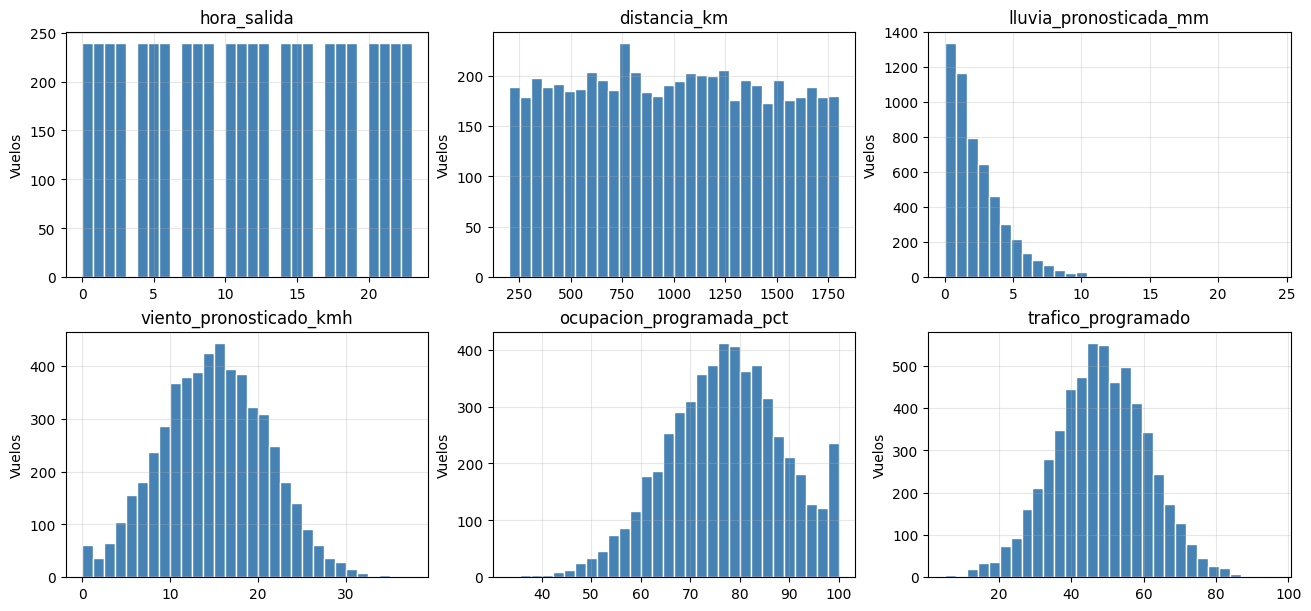

In [5]:
# Distribución de cada variable numérica en entrenamiento.
fig, ax = plt.subplots(2, 3, figsize=(13, 6), constrained_layout=True)
for a, col in zip(ax.ravel(), NUMERICAS):
    a.hist(X_ent[col].dropna(), bins=30, color="steelblue", edgecolor="white")
    a.set(title=col, ylabel="Vuelos")
plt.show()

**Hallazgos de la auditoría.**

- Hay faltantes, cerca del 6 % cada una, en `lluvia_pronosticada_mm`, `viento_pronosticado_kmh`, `ocupacion_programada_pct` y `aerolinea`. Las demás columnas están completas.
- La lluvia tiene cola derecha. El viento y la ocupación tienen límites puestos por el generador: viento entre 0 y 45, ocupación entre 25 y 100.
- **Clases desbalanceadas.** Solo el 2.4 % de los vuelos de entrenamiento se retrasan. Con tan pocos positivos, el accuracy no sirve para comparar modelos (predecir "nunca hay retraso" acertaría el 97.6 %), así que se usa AP.

### Preprocesamiento

Se ajusta **dentro de cada entrenamiento**, nunca con datos posteriores:

- **Numéricas:** los faltantes se llenan con la mediana y luego se estandariza.
- **Categóricas:** los faltantes se llenan con la categoría más frecuente y luego se codifican con one-hot. Con `handle_unknown="ignore"`, una categoría que no apareció en entrenamiento queda codificada con ceros en todo su bloque, en lugar de producir un error.

Para el preprocesamiento se usa scikit-learn, como permite el enunciado.

In [6]:
# Reutilizado de clase: la rama numérica y la categórica de construir_pipeline.
# Mejoras: el estimador final es la logística propia (no la de sklearn).
def construir_preprocesador():
    """Preprocesador sin ajustar: imputación + escalado (numéricas) e imputación + one-hot (categóricas)."""
    numerico = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    categorico = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([("num", numerico, NUMERICAS), ("cat", categorico, CATEGORICAS)])

## 7b. Comparación de modelos con validación cruzada temporal

**Candidatos.** Dos versiones de la logística con L2, ambas propias:

- **sin ponderar:** todos los vuelos pesan lo mismo;
- **ponderada:** cada vuelo pesa $a_c=N/(2N_c)$ según su clase $c$. Como los retrasos son pocos, cada retraso pesa unas 40 veces más que un vuelo puntual.

Cada una se prueba con $\lambda_2\in\{0.001,\ 0.01,\ 0.1,\ 1,\ 10\}$.

**Objetivo ponderado.** Se agregó a `RegresionLogisticaGD.fit(X, y, pesos=a)`:

$$F_a(w,b)=\frac{\sum_n a_{y_n}\,\ell(y_n,z_n)}{\sum_n a_{y_n}}+\frac{\lambda_2}{2}\lVert w\rVert^2.$$

- La pérdida se divide por la suma de los pesos, $\sum_n a_{y_n}$. Con estos pesos esa suma vale exactamente $N$, así que la pérdida y la penalización quedan en la misma proporción que en el modelo sin ponderar.
- La penalización es la misma, y el intercepto no se penaliza.
- Los pesos se recalculan con las etiquetas del entrenamiento de cada pliegue.

**Reglas fijadas antes de ver resultados.**

- **Pliegues.** `TimeSeriesSplit(n_splits=4, gap=24)` dentro de entrenamiento: cada pliegue entrena con el pasado y evalúa en el bloque siguiente, dejando un día de separación. Se verifica que cada evaluación tenga retrasos y no retrasos.
- **Preprocesamiento.** Se vuelve a ajustar en cada pliegue.
- **Criterio.** AP promedio de los pliegues (sin pesos y sin remuestrear).
- **Desempate.** Si dos candidatos difieren en menos de $10^{-6}$, se prefiere el sin ponderar y, después, el mayor $\lambda_2$.
- **Referencias.** Una probabilidad constante igual a la proporción de retrasos del entrenamiento del pliegue, y la decisión de no enviar ninguna alerta.

In [7]:
LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
TOL_EMPATE = 1e-6
C_FP, C_FN = 1, 12              # costo de una falsa alarma y de un retraso sin alerta


def pesos_clase(y):
    """Peso a_c = N / (2 N_c) de cada observación, según su clase.

    Con un 2.4 % de positivos, cada positivo pesa unas 40 veces más que cada negativo,
    y en total las dos clases pesan lo mismo.
    """
    conteos = np.bincount(y, minlength=2)        # [N_0, N_1]
    peso_por_clase = len(y) / (2 * conteos)      # [a_0, a_1]
    return peso_por_clase[y]                     # el peso que le toca a cada fila


def ajustar(X, y, lam2, ponderada):
    """Ajusta el preprocesador y la logística propia usando solo (X, y).

    Returns
    -------
    (preprocesador ajustado, modelo ajustado)
    """
    prep = construir_preprocesador().fit(X)
    pesos = pesos_clase(y) if ponderada else None
    modelo = RegresionLogisticaGD(lam2=lam2).fit(prep.transform(X), y, pesos=pesos)
    assert modelo.motivo_parada_ == "convergencia", modelo.motivo_parada_
    return prep, modelo


def probabilidad(prep, modelo, X):
    """Probabilidad de retraso P(Y = 1 | x) para cada fila de X."""
    return modelo.predict_proba(prep.transform(X))[:, 1]


# Pliegues temporales: cada uno ajusta con el pasado y evalúa en el bloque siguiente.
cortes = list(TimeSeriesSplit(n_splits=4, gap=GAP).split(X_ent))
for i_fit, i_eval in cortes:
    assert i_fit.max() + GAP < i_eval.min()                  # respeta el día de separación
    assert len(np.unique(y_ent[i_eval])) == 2                # la evaluación tiene las dos clases
    assert len(np.unique(y_ent[i_fit])) == 2
print("Tamaños (ajuste, evaluación, positivos en evaluación):",
      [(len(a), len(b), int(y_ent[b].sum())) for a, b in cortes])

filas = []
for k, (i_fit, i_eval) in enumerate(cortes, start=1):
    X_fit, y_fit = X_ent.iloc[i_fit], y_ent[i_fit]          # pasado: para ajustar
    X_eval, y_eval = X_ent.iloc[i_eval], y_ent[i_eval]      # bloque siguiente: para evaluar

    for ponderada in (False, True):
        for lam in LAMBDAS:
            prep, modelo = ajustar(X_fit, y_fit, lam, ponderada)
            p = probabilidad(prep, modelo, X_eval)
            filas.append({"modelo": "ponderada" if ponderada else "sin ponderar", "lambda2": lam,
                          "pliegue": k, "AP": average_precision_score(y_eval, p),
                          "log_loss": log_loss(y_eval, p, labels=[0, 1])})

    # Referencia 1: probabilidad constante = proporción de retrasos del entrenamiento del pliegue.
    p_const = np.full(len(y_eval), y_fit.mean())
    filas.append({"modelo": "referencia: prevalencia", "lambda2": np.nan, "pliegue": k,
                  "AP": average_precision_score(y_eval, p_const),
                  "log_loss": log_loss(y_eval, p_const, labels=[0, 1])})
    # Referencia 2: no alertar nunca (recall 0; cada retraso cuesta C_FN).
    filas.append({"modelo": "referencia: no alertar", "lambda2": np.nan, "pliegue": k,
                  "AP": np.nan, "log_loss": np.nan, "recall": 0.0,
                  "costo": C_FN * y_eval.sum() / len(y_eval)})

# Resultados por pliegue (los pide el taller) y resumen por candidato.
cv = pd.DataFrame(filas)
cv.to_csv(RESULTADOS / "p7_validacion_cv.csv", index=False)
resumen_cv = (cv.groupby(["modelo", "lambda2"], dropna=False, sort=False)
              .agg(AP_media=("AP", "mean"), AP_desv=("AP", "std"),
                   log_loss_media=("log_loss", "mean"), costo_medio=("costo", "mean"))
              .reset_index())
resumen_cv

Tamaños (ajuste, evaluación, positivos en evaluación): [(1124, 1147, 31), (2271, 1147, 27), (3418, 1147, 31), (4565, 1147, 29)]


,modelo,lambda2,AP_media,AP_desv,log_loss_media,costo_medio
0,sin ponderar,0.001,0.2293,0.0643,0.0946,NaN
1,sin ponderar,0.010,0.2357,0.0825,0.0955,NaN
2,sin ponderar,0.100,0.2157,0.0765,0.1095,NaN
3,sin ponderar,1.000,0.2090,0.0807,0.1185,NaN
4,sin ponderar,10.000,0.2088,0.0802,0.1197,NaN
5,ponderada,0.001,0.2264,0.0719,0.4712,NaN
6,ponderada,0.010,0.2379,0.0815,0.4624,NaN
7,ponderada,0.100,0.2465,0.0998,0.4839,NaN
8,ponderada,1.000,0.2234,0.0869,0.5928,NaN
9,ponderada,10.000,0.2107,0.0810,0.6760,NaN


In [8]:
# AP de cada candidato en cada pliegue.
cv_para_tabla = cv.assign(lam=cv["lambda2"].fillna("-"))          # "-" en lugar de NaN para mostrar
cv_para_tabla.pivot_table(index=["modelo", "lam"], columns="pliegue", values="AP", sort=False).round(4)

pliegue                             1       2       3       4
modelo                  lam                                  
sin ponderar            0.001  0.3199  0.1993  0.1722  0.2259
                        0.01   0.3581  0.1805  0.1943  0.2097
                        0.1    0.3275  0.1706  0.2022  0.1625
                        1.0    0.3245  0.1662  0.2020  0.1433
                        10.0   0.3235  0.1662  0.2020  0.1434
ponderada               0.001  0.3263  0.1936  0.1597  0.2258
                        0.01   0.3581  0.1969  0.1799  0.2169
                        0.1    0.3956  0.1892  0.1920  0.2091
                        1.0    0.3510  0.1829  0.2018  0.1581
                        10.0   0.3271  0.1693  0.2017  0.1447
referencia: prevalencia -      0.0270  0.0235  0.0270  0.0253

In [9]:
# --- Selección con la regla fijada antes de ver los resultados ---
modelos_cv = resumen_cv[~resumen_cv["modelo"].str.startswith("referencia")].copy()
mejor_ap = modelos_cv["AP_media"].max()

# Candidatos empatados (a menos de TOL_EMPATE del mejor). Desempate: sin ponderar, luego mayor lambda.
empatados = modelos_cv[modelos_cv["AP_media"] >= mejor_ap - TOL_EMPATE].copy()
empatados["orden"] = (empatados["modelo"] != "sin ponderar").astype(int)     # 0 = sin ponderar
ganador = empatados.sort_values(["orden", "lambda2"], ascending=[True, False]).iloc[0]
GANADOR_PONDERADA = ganador["modelo"] == "ponderada"
GANADOR_LAMBDA = float(ganador["lambda2"])

# El otro candidato final: el mejor lambda del tipo de modelo que no ganó (solo para diagnóstico).
del_otro_tipo = modelos_cv[modelos_cv["modelo"] != ganador["modelo"]]
otro = del_otro_tipo.sort_values(["AP_media", "lambda2"], ascending=[False, False]).iloc[0]

# Historial de selección (lo pide el taller).
seleccion = {
    "criterio": "AP media en 4 pliegues temporales (gap=24) de entrenamiento",
    "desempate": "diferencia < 1e-6 -> sin ponderar, luego mayor lambda2",
    "historial": modelos_cv.sort_values("AP_media", ascending=False)[
        ["modelo", "lambda2", "AP_media", "AP_desv", "log_loss_media"]].to_dict("records"),
    "ganador": {"modelo": ganador["modelo"], "lambda2": GANADOR_LAMBDA, "AP_media": float(ganador["AP_media"])},
    "otro_candidato_final": {"modelo": otro["modelo"], "lambda2": float(otro["lambda2"]),
                             "AP_media": float(otro["AP_media"])},
}
with open(RESULTADOS / "p7_seleccion.json", "w", encoding="utf-8") as f:
    json.dump(seleccion, f, indent=2, ensure_ascii=False)

print(f"Ganador: logística {ganador['modelo']}, lambda2 = {GANADOR_LAMBDA} (AP media {ganador['AP_media']:.4f})")
print(f"Otro candidato final: logística {otro['modelo']}, lambda2 = {otro['lambda2']} (AP media {otro['AP_media']:.4f})")

Ganador: logística ponderada, lambda2 = 0.1 (AP media 0.2465)
Otro candidato final: logística sin ponderar, lambda2 = 0.01 (AP media 0.2357)


**Interpretación.**

- Gana la logística **ponderada con $\lambda_2=0.1$** (AP 0.2465 frente a 0.2357 de la mejor sin ponderar). La ventaja es pequeña y viene casi toda del primer pliegue.
- Todos los modelos ordenan los vuelos unas 9 veces mejor que la referencia constante (AP ≈ 0.026).
- La ponderación empeora mucho la log-loss (0.46–0.68 frente a 0.095): los pesos inflan las probabilidades (problema 3c). La AP no lo nota porque solo mide el orden.
- No alertar cuesta en promedio 0.309 por vuelo.

## 7c. Experimento de fuga y diagnóstico en validación

### Experimento de fuga (solo dentro de entrenamiento)

Se dejan fijos el modelo ganador, su $\lambda_2$ y los 4 pliegues, y se comparan dos formas de preparar los datos:

- **Contaminada:** el preprocesador (medianas, modas, medias y escalas) se ajusta una sola vez con **todo** el entrenamiento, antes de la validación cruzada. Así, cada pliegue usa estadísticas que incluyen su propio bloque de evaluación y bloques del futuro.
- **Correcta:** el preprocesador se vuelve a ajustar en cada pliegue, solo con su pasado.

Los resultados contaminados **no** se usan para elegir nada.

In [10]:
# Preprocesador contaminado: aprende con TODO entrenamiento, incluido el futuro de cada pliegue.
prep_global = construir_preprocesador().fit(X_ent)

filas = []
for k, (i_fit, i_eval) in enumerate(cortes, start=1):
    X_fit, y_fit = X_ent.iloc[i_fit], y_ent[i_fit]
    X_eval, y_eval = X_ent.iloc[i_eval], y_ent[i_eval]

    # Correcto: preprocesador y modelo ajustados solo con el pasado del pliegue.
    prep_ok, modelo_ok = ajustar(X_fit, y_fit, GANADOR_LAMBDA, GANADOR_PONDERADA)
    p_ok = probabilidad(prep_ok, modelo_ok, X_eval)

    # Contaminado: mismo modelo, pero sobre datos transformados con el preprocesador global.
    pesos = pesos_clase(y_fit) if GANADOR_PONDERADA else None
    modelo_mal = RegresionLogisticaGD(lam2=GANADOR_LAMBDA).fit(prep_global.transform(X_fit), y_fit, pesos=pesos)
    p_mal = probabilidad(prep_global, modelo_mal, X_eval)

    filas.append({"pliegue": k,
                  "AP correcto": average_precision_score(y_eval, p_ok),
                  "AP contaminado": average_precision_score(y_eval, p_mal),
                  "log-loss correcto": log_loss(y_eval, p_ok),
                  "log-loss contaminado": log_loss(y_eval, p_mal)})

fuga = pd.DataFrame(filas).set_index("pliegue")
fuga["Δ AP (contam. − correcto)"] = fuga["AP contaminado"] - fuga["AP correcto"]
fuga["Δ log-loss (contam. − correcto)"] = fuga["log-loss contaminado"] - fuga["log-loss correcto"]
display(fuga.round(5))

# Qué información se filtró: medias disponibles en el pliegue 1 frente a las de todo entrenamiento.
i_fit_1 = cortes[0][0]
display(pd.DataFrame({
    "media disponible en el pliegue 1": X_ent.iloc[i_fit_1][NUMERICAS].mean(),
    "media con todo entrenamiento (contaminada)": X_ent[NUMERICAS].mean(),
}).round(3))

,AP correcto,AP contaminado,log-loss correcto,log-loss contaminado,Δ AP (contam. − correcto),Δ log-loss (contam. − correcto)
pliegue,,,,,,
1,0.3956,0.3907,0.4388,0.4366,-0.0049,-2.1600e-03
2,0.1892,0.1858,0.4691,0.4684,-0.0034,-7.0000e-04
3,0.1920,0.1922,0.4781,0.4777,0.0002,-4.0000e-04
4,0.2091,0.2090,0.5497,0.5496,-0.0001,-6.0000e-05


,media disponible en el pliegue 1,media con todo entrenamiento (contaminada)
hora_salida,11.500,11.500
distancia_km,984.975,993.013
lluvia_pronosticada_mm,2.479,2.400
viento_pronosticado_kmh,14.674,14.977
ocupacion_programada_pct,76.684,77.018
trafico_programado,45.785,48.174


**Interpretación.** Las diferencias son mínimas ($|\Delta\text{AP}|\le0.005$) y en 3 de 4 pliegues la versión contaminada sale *peor*. Aun así hubo fuga: en el pliegue 1 la media del tráfico disponible era 45.8, y la versión contaminada usó 48.2, que incluye vuelos futuros.

**¿Por qué el signo o el tamaño de la diferencia no dicen si hubo fuga?** Porque la fuga depende de qué información se usó, no de cuánto cambia la métrica. Aquí lo filtrado (medias y escalas) casi no afecta a la logística, pero con otra transformación la misma fuga podría inflar mucho el resultado. Una diferencia cero no prueba que el procedimiento sea válido.

### Diagnóstico de probabilidades en validación

Los dos candidatos finales (el ganador y el mejor del otro tipo) se entrenan con todo el entrenamiento y se evalúan en validación. Estos diagnósticos **no cambian al ganador**.

- **AP** suma la precisión en cada punto donde sube el recall, como una escalera; el **área trapezoidal** une esos puntos con rectas, por eso da un número algo distinto.
- **Calibración:** se forman 5 grupos del mismo tamaño y se compara la probabilidad predicha con la proporción real de retrasos.

In [11]:
y_val = validacion["retrasado"].to_numpy()
X_val = validacion[PREDICTORES]

# Los dos candidatos finales, entrenados con todo el entrenamiento.
tipo_ganador = "ponderada" if GANADOR_PONDERADA else "sin ponderar"
nombre_ganador = f"{tipo_ganador} λ2={GANADOR_LAMBDA:g} (ganador)"
nombre_otro = f"{otro['modelo']} λ2={otro['lambda2']:g}"
finales = {
    nombre_ganador: ajustar(X_ent, y_ent, GANADOR_LAMBDA, GANADOR_PONDERADA),
    nombre_otro: ajustar(X_ent, y_ent, float(otro["lambda2"]), otro["modelo"] == "ponderada"),
}

# Probabilidades en validación de cada candidato.
p_val = {}
for nombre, (prep, modelo) in finales.items():
    p_val[nombre] = probabilidad(prep, modelo, X_val)

filas = []
for nombre, p in p_val.items():
    precision_c, recall_c, _ = precision_recall_curve(y_val, p)
    filas.append({"modelo": nombre,
                  "AP": average_precision_score(y_val, p),
                  "área trapezoidal PR": auc(recall_c, precision_c),
                  "ROC-AUC": roc_auc_score(y_val, p),
                  "log-loss": log_loss(y_val, p),
                  "Brier": brier_score_loss(y_val, p)})
print(f"Prevalencia en validación: {y_val.mean():.4f} ({y_val.sum()} positivos de {len(y_val)})")
pd.DataFrame(filas).set_index("modelo")

Prevalencia en validación: 0.0390 (74 positivos de 1896)


,AP,área trapezoidal PR,ROC-AUC,log-loss,Brier
modelo,,,,,
ponderada λ2=0.1 (ganador),0.3939,0.3917,0.8528,0.5351,0.1784
sin ponderar λ2=0.01,0.3915,0.3891,0.8512,0.1259,0.0316


ponderada λ2=0.1 (ganador): 5 grupos efectivos


,casos,positivos,p_media,frecuencia
grupo,,,,
"(0.0271, 0.209]",380,0,0.1501,0.0000
"(0.209, 0.305]",379,2,0.2582,0.0053
"(0.305, 0.42]",379,9,0.3602,0.0237
"(0.42, 0.57]",379,9,0.4899,0.0237
"(0.57, 0.989]",379,54,0.7003,0.1425


sin ponderar λ2=0.01: 5 grupos efectivos


,casos,positivos,p_media,frecuencia
grupo,,,,
"(-0.000227, 0.00767]",380,0,0.0051,0.0000
"(0.00767, 0.0127]",379,2,0.0101,0.0053
"(0.0127, 0.0214]",379,9,0.0166,0.0237
"(0.0214, 0.04]",379,10,0.0290,0.0264
"(0.04, 0.815]",379,53,0.0902,0.1398


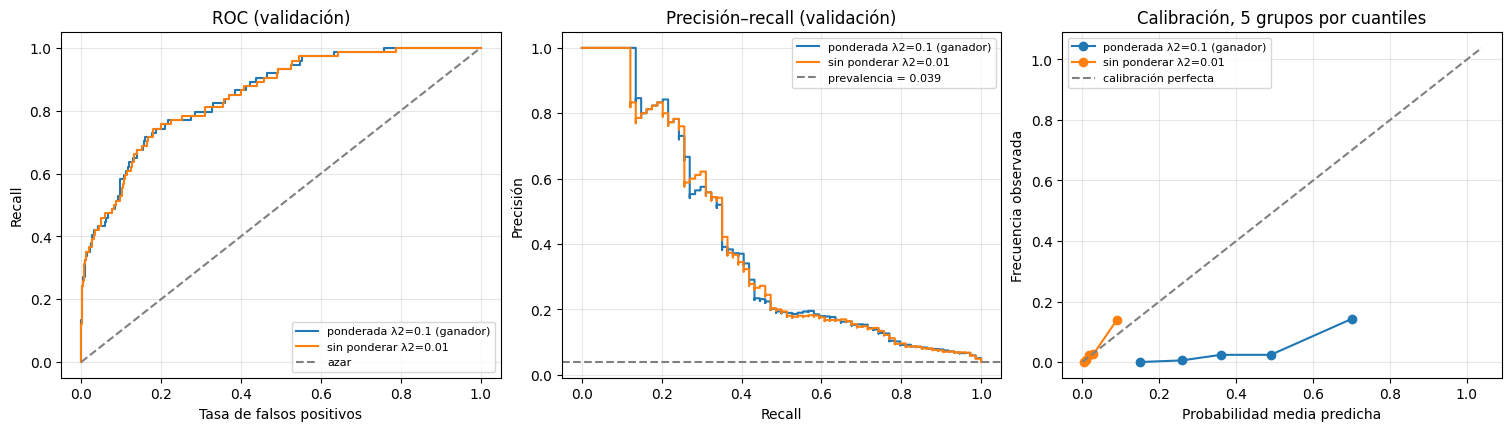

In [12]:
def tabla_calibracion(y, p, grupos=5):
    """Tabla de calibración con grupos del mismo tamaño según los cuantiles de p.

    Para cada grupo: número de casos, número de positivos, probabilidad media
    predicha y frecuencia real de positivos. Si hay probabilidades repetidas,
    qcut puede fusionar grupos (duplicates="drop"); el largo de la tabla dice
    cuántos grupos quedaron.
    """
    grupo = pd.qcut(p, grupos, duplicates="drop")
    tabla = pd.DataFrame({"y": y, "p": p, "grupo": grupo})
    return tabla.groupby("grupo", observed=True).agg(
        casos=("y", "size"), positivos=("y", "sum"), p_media=("p", "mean"), frecuencia=("y", "mean"))


fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for nombre, p in p_val.items():
    fpr, tpr, _ = roc_curve(y_val, p)
    precision_c, recall_c, _ = precision_recall_curve(y_val, p)
    cal = tabla_calibracion(y_val, p)

    ax[0].plot(fpr, tpr, label=nombre)
    ax[1].step(recall_c, precision_c, where="post", label=nombre)
    ax[2].plot(cal["p_media"], cal["frecuencia"], "o-", label=nombre)
    print(f"{nombre}: {len(cal)} grupos efectivos")
    display(cal.round(4))

ax[0].plot([0, 1], [0, 1], "--", color="gray", label="azar")
ax[0].set(xlabel="Tasa de falsos positivos", ylabel="Recall", title="ROC (validación)")
ax[1].axhline(y_val.mean(), ls="--", color="gray", label=f"prevalencia = {y_val.mean():.3f}")
ax[1].set(xlabel="Recall", ylabel="Precisión", title="Precisión–recall (validación)")
limite = max(max(p.max() for p in p_val.values()), y_val.mean()) * 1.05
ax[2].plot([0, limite], [0, limite], "--", color="gray", label="calibración perfecta")
ax[2].set(xlabel="Probabilidad media predicha", ylabel="Frecuencia observada",
          title="Calibración, 5 grupos por cuantiles")
for a in ax:
    a.legend(fontsize=8)
plt.show()

**Interpretación.**

- Los dos ordenan casi igual: AP 0.394 frente a 0.392 y ROC-AUC 0.853 frente a 0.851. La AP (0.3939) y el área trapezoidal (0.3917) difieren un poco.
- La diferencia está en la calibración. La ponderada predice probabilidades muy por encima de la realidad (su grupo más alto predice 0.70 y se retrasa el 14 %), con log-loss 0.535. La sin ponderar queda cerca de la diagonal, con log-loss 0.126. Es lo que dice el problema 3c: con pesos, el modelo aprende $q^\star=\frac{a_1p}{a_1p+a_0(1-p)}$ en lugar de $p$.
- Los 5 grupos son efectivos (no hay probabilidades repetidas). El ganador sigue siendo la ponderada.

## 7d. Política de alertas en validación

Una política de alertas es un umbral $\tau$: se alerta a los vuelos con probabilidad $p\ge\tau$. Las probabilidades de validación del ganador quedan fijas y se prueban:

- todos los valores distintos de probabilidad como umbral;
- **"alertar a todos"** ($\tau=0$);
- **"no alertar a nadie"**, con $\tau=+\infty$. Así funciona aunque alguna probabilidad redondee a 1.

La columna `modo` marca estas dos políticas extremas.

**Condiciones del taller:**

- detectar al menos el 80 % de los retrasos (recall $\ge0.80$);
- alertar como máximo al 15 % de los vuelos ($(TP+FP)/N\le0.15$);
- el costo por vuelo es $\hat C(\tau)=(12\,FN+FP)/N$: cada retraso sin alerta cuesta 12 y cada falsa alarma cuesta 1.

**Cómo se elige.** Entre las políticas que cumplen las dos condiciones (factibles) se elige la de menor costo; si empatan, la que menos alerta y luego la de mayor umbral. Si ninguna las cumple, el resultado es **inviabilidad empírica**: se reporta el máximo recall posible con hasta 15 % de alertas y la menor tasa de alertas que logra recall 0.80, y se congela como referencia (no como política aprobada) el umbral de menor costo sin restricciones.

**Comparaciones.**

- $\tau=0.5$, el umbral por defecto.
- El umbral teórico del problema 3b, $\tau^\star=C_{FP}/(C_{FP}+C_{FN})=1/13\approx0.0769$. Ese umbral es el mejor **solo si $p$ es la probabilidad verdadera** de retraso. Con probabilidades estimadas, y posiblemente mal calibradas, no hay garantía.

In [13]:
RECALL_MIN = 0.80
TASA_MAX = 0.15
TAU_TEORICO = C_FP / (C_FP + C_FN)        # 1/13

# Modelo ganador y sus probabilidades de validación (quedan fijas).
NOMBRE_GANADOR = nombre_ganador
prep_g, modelo_g = finales[NOMBRE_GANADOR]
p_g = p_val[NOMBRE_GANADOR]


def conteos(y, alerta):
    """TP, FP, FN y TN calculados directamente con NumPy.

    `alerta` es un arreglo booleano: True si se envía alerta a ese vuelo.
    """
    tp = int(np.sum(alerta & (y == 1)))       # retraso con alerta
    fp = int(np.sum(alerta & (y == 0)))       # falsa alarma
    fn = int(np.sum(~alerta & (y == 1)))      # retraso sin alerta
    tn = int(np.sum(~alerta & (y == 0)))      # vuelo puntual sin alerta
    return tp, fp, fn, tn


def fila_politica(y, p, tau, modo="umbral"):
    """Resultado de la política "alertar si p >= tau": conteos, recall, precisión, tasa de alertas y costo."""
    alerta = p >= tau
    tp, fp, fn, tn = conteos(y, alerta)
    precision = tp / (tp + fp) if tp + fp else np.nan      # sin alertas, la precisión no está definida
    return {"tau": tau, "modo": modo, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "recall": tp / (tp + fn), "precision": precision,
            "tasa_alertas": (tp + fp) / len(y),
            "costo": (C_FN * fn + C_FP * fp) / len(y)}


# Tabla de umbrales: alertar a todos, cada probabilidad distinta y no alertar a nadie.
filas = [fila_politica(y_val, p_g, 0.0, "alertar_todos")]
for tau in np.unique(p_g):
    filas.append(fila_politica(y_val, p_g, tau))
filas.append(fila_politica(y_val, p_g, np.inf, "no_alertar"))

umbrales = pd.DataFrame(filas)
umbrales["factible"] = (umbrales["recall"] >= RECALL_MIN) & (umbrales["tasa_alertas"] <= TASA_MAX)
assert (umbrales[["TP", "FP", "FN", "TN"]].sum(axis=1) == len(y_val)).all()
umbrales.to_csv(RESULTADOS / "p7_tabla_umbrales.csv", index=False)

# Orden de preferencia: menor costo, luego menor tasa de alertas, luego mayor umbral.
orden = ["costo", "tasa_alertas", "tau"]
ascendente = [True, True, False]
factibles = umbrales[umbrales["factible"]]

if len(factibles) > 0:
    ESTADO = "factible"
    politica = factibles.sort_values(orden, ascending=ascendente).iloc[0]
else:
    ESTADO = "inviabilidad empírica"
    # Lo mejor que se puede lograr con cada restricción por separado.
    con_pocas_alertas = umbrales[umbrales["tasa_alertas"] <= TASA_MAX]
    max_recall = con_pocas_alertas.sort_values(["recall", "tasa_alertas"], ascending=[False, True]).iloc[0]
    con_buen_recall = umbrales[umbrales["recall"] >= RECALL_MIN]
    min_tasa = con_buen_recall.sort_values(["tasa_alertas", "tau"], ascending=[True, False]).iloc[0]
    # Referencia diagnóstica: menor costo sin restricciones (no es una política aprobada).
    politica = umbrales.sort_values(orden, ascending=ascendente).iloc[0]

print(f"Políticas evaluadas: {len(umbrales)} | factibles: {len(factibles)} | estado: {ESTADO}")

# Comparación de la política elegida (o diagnóstica) con tau = 0.5 y con el umbral teórico.
nombre_politica = "seleccionada" if ESTADO == "factible" else "diagnóstica (menor costo sin restricciones)"
comparacion = pd.DataFrame({
    nombre_politica: politica,
    "tau = 0.5": pd.Series(fila_politica(y_val, p_g, 0.5)),
    "tau teórico = 1/13": pd.Series(fila_politica(y_val, p_g, TAU_TEORICO)),
}).T
if ESTADO != "factible":
    comparacion.loc["máximo recall con tasa <= 0.15"] = max_recall
    comparacion.loc["menor tasa con recall >= 0.80"] = min_tasa
comparacion[["tau", "modo", "TP", "FP", "FN", "TN", "recall", "precision", "tasa_alertas", "costo"]]

Políticas evaluadas: 1898 | factibles: 0 | estado: inviabilidad empírica


,tau,modo,TP,FP,FN,TN,recall,precision,tasa_alertas,costo
diagnóstica (menor costo sin restricciones),0.6351,umbral,47,219,27,1603,0.6351,0.1767,0.1403,0.2864
tau = 0.5,0.5,umbral,57,474,17,1348,0.7703,0.1073,0.2801,0.3576
tau teórico = 1/13,0.0769,umbral,74,1794,0,28,1.0,0.0396,0.9852,0.9462
máximo recall con tasa <= 0.15,0.6351,umbral,47,219,27,1603,0.6351,0.1767,0.1403,0.2864
menor tasa con recall >= 0.80,0.4546,umbral,60,596,14,1226,0.8108,0.0915,0.346,0.403


**Interpretación.**

**Resultado: inviabilidad empírica.** Ninguna de las 1898 políticas cumple a la vez recall $\ge0.80$ y alertas $\le15\,\%$:

- con hasta 15 % de alertas, el máximo recall es 0.635 ($\tau=0.6351$);
- para llegar a recall 0.80 hay que alertar al menos al 34.6 % de los vuelos ($\tau=0.4546$).

No se cambian los límites ni los datos. Como referencia diagnóstica (no como política aprobada) se congela el umbral de menor costo, $\tau=0.6351$, con costo 0.286 por vuelo (no alertar cuesta 0.469).

**Comparaciones.** $\tau=0.5$ logra recall 0.770 alertando al 28 % de los vuelos. El umbral teórico $1/13$ alerta al 98.5 % de los vuelos: supone que $p$ es la probabilidad verdadera, y las probabilidades del modelo ponderado están muy por encima de la realidad.

## 7e. Manifiesto y evaluación final en prueba

**Antes** de abrir prueba se guarda un manifiesto, es decir, un archivo con todo lo necesario para repetir la decisión:

- las variables;
- el preprocesamiento, con los valores aprendidos (medianas, medias, escalas, categorías);
- los parámetros del modelo;
- la regla de decisión;
- los umbrales sin redondear (JSON guarda cada número con todos sus dígitos).

El modelo **no** se vuelve a entrenar con entrenamiento más validación: eso cambiaría las probabilidades con las que se eligió el umbral.

In [14]:
# Valores aprendidos por el preprocesador del ganador.
num = prep_g.named_transformers_["num"]
cat = prep_g.named_transformers_["cat"]

# Las tres políticas que se evaluarán en prueba.
clave_politica = "tau_seleccionado" if ESTADO == "factible" else "tau_diagnostico"
POLITICAS = {"tau_0.5": 0.5, "tau_teorico": TAU_TEORICO, clave_politica: float(politica["tau"])}

ids_entrenamiento = (entrenamiento["id_vuelo"].min(), entrenamiento["id_vuelo"].max())
manifiesto = {
    "variables": PREDICTORES,
    "preprocesamiento": {
        "numericas": {"variables": NUMERICAS,
                      "imputacion_mediana": num["imputar"].statistics_.tolist(),
                      "media": num["escalar"].mean_.tolist(),
                      "escala": num["escalar"].scale_.tolist()},
        "categoricas": {"variables": CATEGORICAS,
                        "imputacion_moda": cat["imputar"].statistics_.tolist(),
                        "categorias": [c.tolist() for c in cat["codificar"].categories_],
                        "categoria_nueva": "bloque one-hot en ceros"},
        "ajustado_con": "entrenamiento (ids %d-%d)" % ids_entrenamiento,
    },
    "modelo": {"clase": "RegresionLogisticaGD", "ponderada": bool(GANADOR_PONDERADA), "lambda2": GANADOR_LAMBDA,
               "columnas": prep_g.get_feature_names_out().tolist(),
               "coef": modelo_g.coef_.tolist(), "intercept": modelo_g.intercept_},
    "regla": "alerta si p >= tau",
    "estado_politica": ESTADO,
    "politicas": POLITICAS,
    "restricciones": {"recall_min": RECALL_MIN, "tasa_alertas_max": TASA_MAX, "costo": "(12 FN + FP) / N"},
}
RUTA_MANIFIESTO = RESULTADOS / "p7_manifiesto_politica.json"
with open(RUTA_MANIFIESTO, "w", encoding="utf-8") as f:
    json.dump(manifiesto, f, indent=2, ensure_ascii=False)
modelo_g.guardar_parametros(PARAMETROS / "p7_logistica.json")
print(json.dumps(POLITICAS, indent=2))

{
  "tau_0.5": 0.5,
  "tau_teorico": 0.07692307692307693,
  "tau_diagnostico": 0.6351112455227611
}


### Evaluación única en prueba

Las probabilidades de prueba se calculan una sola vez con el modelo congelado, y los umbrales se leen del manifiesto guardado.

- $TP$, $TN$, $FP$ y $FN$ se cuentan con NumPy y se comparan con `confusion_matrix` de scikit-learn.
- Las métricas que dependen solo de las probabilidades (AP, ROC-AUC, log-loss y Brier) deben salir idénticas para las tres políticas, porque el umbral no las afecta.

In [15]:
# Los umbrales se leen del archivo guardado antes de abrir prueba.
with open(RUTA_MANIFIESTO, encoding="utf-8") as f:
    politicas_congeladas = json.load(f)["politicas"]

X_pru = prueba[PREDICTORES]
y_pru = prueba["retrasado"].to_numpy()
p_pru = probabilidad(prep_g, modelo_g, X_pru)          # única pasada del modelo por prueba

filas = []
for nombre, tau in politicas_congeladas.items():
    alerta = p_pru >= tau
    tp, fp, fn, tn = conteos(y_pru, alerta)

    # Verificación de los conteos contra scikit-learn (ravel da el orden TN, FP, FN, TP).
    matriz = confusion_matrix(y_pru, alerta.astype(int), labels=[0, 1])
    assert np.array_equal(matriz.ravel(), [tn, fp, fn, tp])

    # Métricas de la decisión (dependen del umbral).
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn)
    especificidad = tn / (tn + fp)
    f1 = 2 * tp / (2 * tp + fp + fn)
    accuracy = (tp + tn) / len(y_pru)
    tasa_alertas = (tp + fp) / len(y_pru)

    fila = {"política": nombre, "tau": tau, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": precision, "recall": recall, "especificidad": especificidad,
            "F1": f1, "accuracy": accuracy,
            # Métricas de las probabilidades (no dependen del umbral).
            "AP": average_precision_score(y_pru, p_pru), "ROC-AUC": roc_auc_score(y_pru, p_pru),
            "log-loss": log_loss(y_pru, p_pru), "Brier": brier_score_loss(y_pru, p_pru),
            "costo": (C_FN * fn + C_FP * fp) / len(y_pru),
            "alertas por 1000": 1000 * (tp + fp) / len(y_pru)}

    # Verificación de las métricas de decisión contra scikit-learn.
    np.testing.assert_allclose(
        [precision, recall, f1, accuracy],
        [precision_score(y_pru, alerta, zero_division=np.nan), recall_score(y_pru, alerta),
         f1_score(y_pru, alerta), accuracy_score(y_pru, alerta)])

    fila["cumple recall >= 0.80"] = recall >= RECALL_MIN
    fila["cumple alertas <= 15 %"] = tasa_alertas <= TASA_MAX
    filas.append(fila)

final = pd.DataFrame(filas).set_index("política")
for metrica in ("AP", "ROC-AUC", "log-loss", "Brier"):        # iguales en las tres políticas
    assert final[metrica].nunique() == 1
final.to_csv(RESULTADOS / "p7_evaluacion_final.csv")

# Predicciones finales con id, fecha, etiqueta observada, probabilidad y decisión de cada política.
salida = prueba[["id_vuelo", "fecha_prediccion", "retrasado"]].copy()
salida["probabilidad"] = p_pru
for nombre, tau in politicas_congeladas.items():
    salida[f"alerta_{nombre}"] = (p_pru >= tau).astype(int)
salida.to_csv(RESULTADOS / "p7_predicciones_prueba.csv", index=False)

print(f"Prevalencia en prueba: {y_pru.mean():.4f} ({y_pru.sum()} positivos de {len(y_pru)})")
final.T

Prevalencia en prueba: 0.0370 (71 positivos de 1920)


política,tau_0.5,tau_teorico,tau_diagnostico
tau,0.5,0.0769,0.6351
TP,57,71,50
FP,565,1821,234
FN,14,0,21
TN,1284,28,1615
precision,0.0916,0.0375,0.1761
recall,0.8028,1.0,0.7042
especificidad,0.6944,0.0151,0.8734
F1,0.1645,0.0723,0.2817
accuracy,0.6984,0.0516,0.8672


**Interpretación.** Los conteos de NumPy coinciden con scikit-learn, y AP (0.409), ROC-AUC (0.869), log-loss (0.561) y Brier (0.191) son iguales en las tres políticas porque no dependen del umbral.

| Política | Recall | Alertas por 1000 vuelos | Costo por vuelo | ¿Cumple las dos condiciones? |
|---|---|---|---|---|
| Diagnóstica ($\tau=0.6351$) | 0.704 | 148 | 0.253 (el menor) | No: cumple alertas, no recall |
| $\tau=0.5$ | 0.803 | 324 | 0.382 | No: cumple recall, no alertas |
| $\tau^\star=1/13$ | 1.0 | 985 | 0.948 | No: alerta a casi todos |

Ninguna política cumple las dos condiciones en prueba, igual que en validación.

**¿Por qué cumplir en validación no garantizaba cumplir en prueba?** Porque hay pocos retrasos (unos 70), así que el recall cambia bastante por azar; porque prueba es otro período, con más tráfico; y porque el umbral se eligió mirando validación, donde su resultado es optimista. La política no se ajusta después de ver prueba.